# Ajustes polinómicos — carrito en plano inclinado
**Objetivo:** comprender `polyfit`, `polyval` y por qué más grado no siempre significa mejor modelo físico.

## 1. Datos y modelo
El archivo contiene tiempo $t$ (s) y posición $x$ (cm). Para aceleración aproximadamente constante: $x(t)=x_0+v_0t+\tfrac12at^2$. Por eso un polinomio de grado 2 tiene interpretación física.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('bmh')

datos = np.genfromtxt('carro-inclinado.txt')
t, posicion_cm = datos.T
print('Datos:', len(t))

Datos: 10


## 2. Ajustar y observar residuos
`np.polyfit(t, x, grado)` devuelve coeficientes desde la potencia mayor a la menor; `np.polyval` evalúa el modelo.

In [2]:
def ajuste_polinomico(grado):
    coef = np.polyfit(t, posicion_cm, grado)
    estimado = np.polyval(coef, t)
    suma_cuadrados = np.sum((posicion_cm - estimado)**2)
    return coef, suma_cuadrados

for grado in (1, 2, 5):
    coef, sc = ajuste_polinomico(grado)
    print(f'Grado {grado}: suma de residuos² = {sc:.3f} cm²')

Grado 1: suma de residuos² = 588.474 cm²
Grado 2: suma de residuos² = 1.659 cm²
Grado 5: suma de residuos² = 1.452 cm²


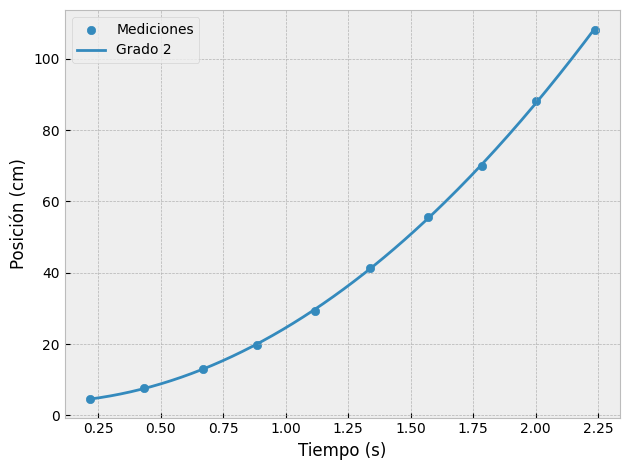

Aceleración inferida del coeficiente cuadrático: 0.420 m/s²


In [3]:
coef2, _ = ajuste_polinomico(2)
t_recta = np.linspace(t.min(), t.max(), 200)
plt.scatter(t, posicion_cm, label='Mediciones')
plt.plot(t_recta, np.polyval(coef2, t_recta), label='Grado 2')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (cm)')
plt.legend()
plt.tight_layout()
plt.show()
aceleracion = 2 * coef2[0] / 100  # cm/s² a m/s²
print(f'Aceleración inferida del coeficiente cuadrático: {aceleracion:.3f} m/s²')

**Precaución:** en el notebook original se probaba grado 200 con 10 datos. Ese grado no permite un ajuste polinómico determinado por los datos y genera problemas numéricos. La comparación 1, 2 y 5 mantiene la idea sin utilizar un caso inválido.

**Comprueba:** ¿por qué el grado 2 está motivado por el modelo de movimiento uniformemente acelerado? ¿Un residuo cuadrático menor prueba que el modelo sea físicamente mejor?